**Nạp dữ liệu**



In [169]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LinearRegression
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import Lasso, Ridge

In [170]:
df = pd.read_csv("Social_Network_Ads.csv")

In [171]:
df.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [172]:
df.describe()

,User ID,Age,EstimatedSalary,Purchased
count,4.000000e+02,400.000000,400.000000,400.000000
mean,1.569154e+07,37.655000,69742.500000,0.357500
std,7.165832e+04,10.482877,34096.960282,0.479864
min,1.556669e+07,18.000000,15000.000000,0.000000
25%,1.562676e+07,29.750000,43000.000000,0.000000
50%,1.569434e+07,37.000000,70000.000000,0.000000
75%,1.575036e+07,46.000000,88000.000000,1.000000
max,1.581524e+07,60.000000,150000.000000,1.000000


In [173]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   User ID          400 non-null    int64
 1   Gender           400 non-null    str  
 2   Age              400 non-null    int64
 3   EstimatedSalary  400 non-null    int64
 4   Purchased        400 non-null    int64
dtypes: int64(4), str(1)
memory usage: 15.8 KB


In [174]:
Missing_values = df.isnull().sum()
print("Missing values in each column:\n", Missing_values)

Missing values in each column:
 User ID            0
Gender             0
Age                0
EstimatedSalary    0
Purchased          0
dtype: int64


In [175]:
gender_mapping = {"Male": 0, "Female": 1}
df["Gender"] = df["Gender"].map(gender_mapping)

**Phân chia dữ liệu train/test**

In [176]:
X = df[["Gender","Age","EstimatedSalary"]]

In [177]:
y = df["Purchased"]

In [178]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42)

In [179]:
scaler = StandardScaler()

In [180]:
X_train_scaled = scaler.fit_transform(X_train)

In [181]:
X_test_scaled = scaler.transform(X_test)

**Logistic Regression**

In [182]:
model = LogisticRegression(random_state=42)

In [183]:
model.fit(X_train_scaled, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following a

In [184]:
y_pred = model.predict(X_test_scaled)

In [185]:
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

In [186]:
print("Độ chính xác của Logistic Regression qua precision_score:", round(prec*100,2),"%" )
print("Độ chính xác của Logistic Regression qua accuracy_score:", round(acc*100,2),"%")
print("Độ chính xác của Logistic Regression qua recall_score", round(rec*100,2),"%")
print("Độ chính xác của Logistic Regression qua F1_score:", round(f1*100,2),"%")

Độ chính xác của Logistic Regression qua precision_score: 91.3 %
Độ chính xác của Logistic Regression qua accuracy_score: 88.75 %
Độ chính xác của Logistic Regression qua recall_score 75.0 %
Độ chính xác của Logistic Regression qua F1_score: 82.35 %


In [187]:
print(confusion_matrix(y_test, y_pred))

[[50  2]
 [ 7 21]]


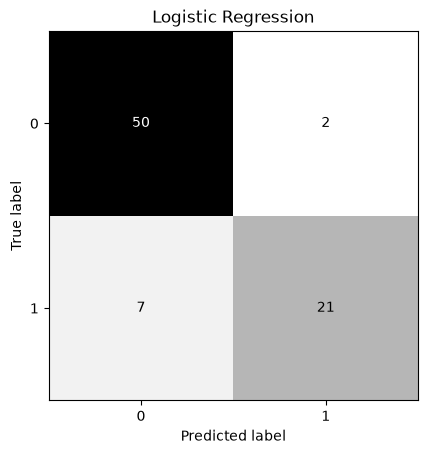

In [188]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, colorbar=False, cmap='Greys')
plt.title("Logistic Regression")
plt.show()

**Decision Tree**

In [189]:
model_Tree = DecisionTreeClassifier(random_state=42)

In [190]:
model_Tree.fit(X_train_scaled, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [191]:
y_pred_Tree = model_Tree.predict(X_test_scaled)

In [192]:
acc_Tree = accuracy_score(y_test, y_pred_Tree)
prec_Tree = precision_score(y_test, y_pred_Tree)
rec_Tree = recall_score(y_test, y_pred_Tree)
f1_Tree = f1_score(y_test, y_pred_Tree)

In [193]:
print("Độ chính xác của Decision Tree qua precision_score:", round(prec_Tree*100,2),"%")
print("Độ chính xác của Decision Tree qua accuracy_score:", round(acc_Tree*100,2),"%")
print("Độ chính xác của Decision Tree qua recall_score", round(rec_Tree*100,2),"%")
print("Độ chính xác của Decision Tree qua F1_score:", round(f1_Tree*100,2),"%")

Độ chính xác của Decision Tree qua precision_score: 80.0 %
Độ chính xác của Decision Tree qua accuracy_score: 83.75 %
Độ chính xác của Decision Tree qua recall_score 71.43 %
Độ chính xác của Decision Tree qua F1_score: 75.47 %


In [194]:
print(confusion_matrix(y_test, y_pred_Tree))

[[47  5]
 [ 8 20]]


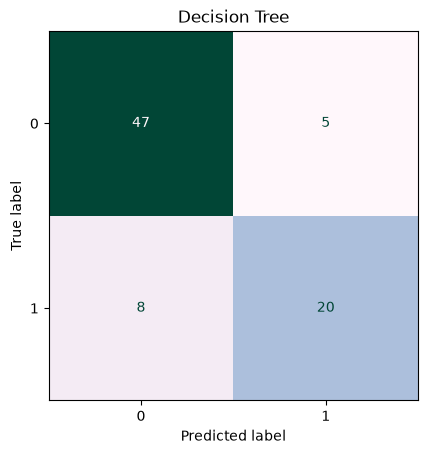

In [195]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_Tree, colorbar=False, cmap='PuBuGn')
plt.title("Decision Tree")
plt.show()

**Random Forest**

In [196]:
rf_model = RandomForestClassifier(n_estimators=150, random_state=42)

In [197]:
rf_model.fit(X_train_scaled, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",150
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [198]:
y_pred_rf = rf_model.predict(X_test_scaled)

In [199]:
acc_rf = accuracy_score(y_test, y_pred_rf)
prec_rf = precision_score(y_test, y_pred_rf)
rec_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)

In [200]:
print("Độ chính xác của RandomForest qua precision_score:", round(prec_rf*100,2),"%")
print("Độ chính xác của RandomForest qua accuracy_score:", round(acc_rf*100,2),"%")
print("Độ chính xác của RandomForest qua recall_score", round(rec_rf*100,2),"%")
print("Độ chính xác của RandomForest qua F1_score:", round(f1_rf*100,2),"%")

Độ chính xác của RandomForest qua precision_score: 83.33 %
Độ chính xác của RandomForest qua accuracy_score: 90.0 %
Độ chính xác của RandomForest qua recall_score 89.29 %
Độ chính xác của RandomForest qua F1_score: 86.21 %


In [201]:
print(confusion_matrix(y_test, y_pred_rf))

[[47  5]
 [ 3 25]]


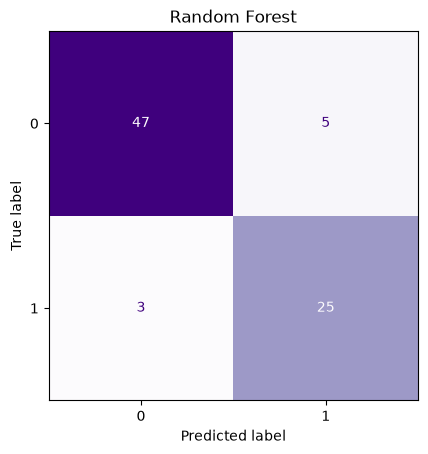

In [202]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_rf, colorbar=False, cmap='Purples')
plt.title("Random Forest")
plt.show()

**Linear Regression**

In [203]:
LR_model = LinearRegression()

In [204]:
LR_model.fit(X_train_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[-0.01, 0.26, 0.15]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.3594
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](3,)","[19.45,17.53,16.57]"


In [205]:
y_pred_LR = LR_model.predict(X_test_scaled)

In [206]:
y_pred_LR_binary = (y_pred_LR >= 0.5).astype(int)

In [207]:
acc_LR = accuracy_score(y_test, y_pred_LR_binary)
prec_LR = precision_score(y_test, y_pred_LR_binary)
rec_LR = recall_score(y_test, y_pred_LR_binary)
f1_LR = f1_score(y_test, y_pred_LR_binary)

In [208]:
print("Độ chính xác của LinearRegression qua precision_score:", round(prec_LR*100,2),"%")
print("Độ chính xác của LinearRegression qua accuracy_score:", round(acc_LR*100,2),"%")
print("Độ chính xác của LinearRegression qua recall_score", round(rec_LR*100,2),"%")
print("Độ chính xác của LinearRegression qua F1_score:", round(f1_LR*100,2),"%")

Độ chính xác của LinearRegression qua precision_score: 91.3 %
Độ chính xác của LinearRegression qua accuracy_score: 88.75 %
Độ chính xác của LinearRegression qua recall_score 75.0 %
Độ chính xác của LinearRegression qua F1_score: 82.35 %


In [209]:
print(confusion_matrix(y_test, y_pred_LR_binary))

[[50  2]
 [ 7 21]]


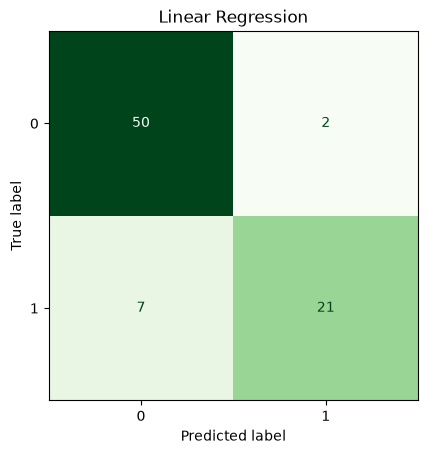

In [210]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_LR_binary, colorbar=False, cmap='Greens')
plt.title("Linear Regression")
plt.show()

**MLPClassifier**

In [211]:
model_MLP = MLPClassifier(hidden_layer_sizes=(16, 8), max_iter=2000, random_state=42)
model_MLP = model_MLP.fit(X_train_scaled, y_train)

In [212]:
y_pred_MLP = model_MLP.predict(X_test_scaled)

In [213]:
acc_MLP = accuracy_score(y_test, y_pred_MLP)
prec_MLP = precision_score(y_test, y_pred_MLP)
rec_MLP = recall_score(y_test, y_pred_MLP)
f1_MLP = f1_score(y_test, y_pred_MLP)

In [214]:
print("Độ chính xác của MLPClassifier qua precision_score:", round(prec_MLP*100,2),"%")
print("Độ chính xác của MLPClassifier qua accuracy_score:", round(acc_MLP*100,2),"%")
print("Độ chính xác của MLPClassifier qua recall_score", round(rec_MLP*100,2),"%")
print("Độ chính xác của MLPClassifier qua F1_score:", round(f1_MLP*100,2),"%")

Độ chính xác của MLPClassifier qua precision_score: 83.87 %
Độ chính xác của MLPClassifier qua accuracy_score: 91.25 %
Độ chính xác của MLPClassifier qua recall_score 92.86 %
Độ chính xác của MLPClassifier qua F1_score: 88.14 %


In [215]:
print(confusion_matrix(y_test, y_pred_MLP))

[[47  5]
 [ 2 26]]


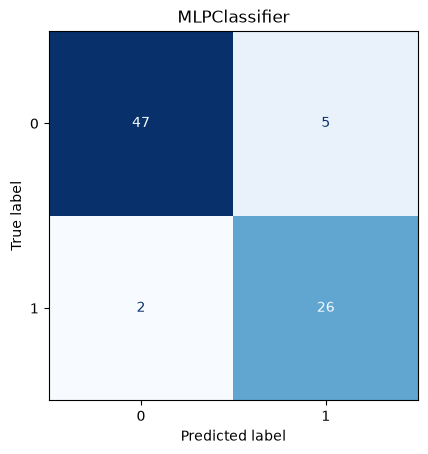

In [216]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_MLP, colorbar=False, cmap='Blues')
plt.title("MLPClassifier")
plt.show()

## thay đổi feature

In [217]:
feature_1 = ["Age", "EstimatedSalary"]

In [218]:
X_feature_1 = df[feature_1]

In [219]:
X_train_feature_1, X_test_feature_1, y_train_feature_1, y_test_feature_1 = train_test_split(X_feature_1, y, test_size=0.2, random_state=42)

In [220]:
X_train_feature_1_scaled = scaler.fit_transform(X_train_feature_1)
X_test_feature_1_scaled = scaler.transform(X_test_feature_1)

In [221]:
model_feature = LogisticRegression()
model_Tree_feature = DecisionTreeClassifier(random_state=42)
model_rf_feature = RandomForestClassifier(n_estimators=150, random_state=42)
model_LR_feature = LinearRegression()
model_MLP_feature = MLPClassifier(hidden_layer_sizes=(16, 8), max_iter=2000, random_state=42)

In [222]:
model_feature.fit(X_train_feature_1_scaled, y_train)
model_Tree_feature.fit(X_train_feature_1_scaled, y_train)
model_rf_feature.fit(X_train_feature_1_scaled, y_train)
model_LR_feature.fit(X_train_feature_1_scaled, y_train)
model_MLP_feature.fit(X_train_feature_1_scaled, y_train)

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(16, ...)"
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",2000
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


In [223]:
model_feature_pred = model_feature.predict(X_test_feature_1_scaled)
model_Tree_feature_pred = model_Tree_feature.predict(X_test_feature_1_scaled)
model_rf_feature_pred = model_rf_feature.predict(X_test_feature_1_scaled)
model_LR_feature_pred = model_LR_feature.predict(X_test_feature_1_scaled)
model_MLP_feature_pred = model_MLP_feature.predict(X_test_feature_1_scaled)

In [224]:
y_pred_LR_binary_feature = (model_LR_feature_pred >= 0.5).astype(int)

In [225]:
acc_feature = accuracy_score(y_test, model_feature_pred)
acc_Tree_feature = accuracy_score(y_test, model_Tree_feature_pred)
acc_rf_feature = accuracy_score(y_test, model_rf_feature_pred)
acc_LR_feature = accuracy_score(y_test, y_pred_LR_binary_feature)
acc_MLP_feature = accuracy_score(y_test, model_MLP_feature_pred)

In [226]:
print("Độ chính xác của Logistic Regression qua accuracy_score:", round(acc_feature*100,2),"%")
print("Độ chính xác của Decision Tree qua accuracy_score:", round(acc_Tree_feature*100,2),"%")
print("Độ chính xác của RandomForest qua accuracy_score:", round(acc_rf_feature*100,2),"%")
print("Độ chính xác của LinearRegression qua accuracy_score:", round(acc_LR_feature*100,2),"%")
print("Độ chính xác của MLPClassifier qua accuracy_score:", round(acc_MLP_feature*100,2),"%")

Độ chính xác của Logistic Regression qua accuracy_score: 86.25 %
Độ chính xác của Decision Tree qua accuracy_score: 83.75 %
Độ chính xác của RandomForest qua accuracy_score: 87.5 %
Độ chính xác của LinearRegression qua accuracy_score: 86.25 %
Độ chính xác của MLPClassifier qua accuracy_score: 92.5 %


**Thay đổi features --> Bỏ Age thì độ chính xác giảm**

In [227]:
feature = ["EstimatedSalary"]

In [228]:
X_feature = df[feature]

In [229]:
X_train_feature, X_test_feature, y_train_feature, y_test_feature = train_test_split(X_feature,y, test_size=0.2, random_state=42)

In [230]:
X_train_feature_scaled = scaler.fit_transform(X_train_feature)
X_test_feature_scaled = scaler.transform(X_test_feature)

In [231]:
model_feature = LogisticRegression()
model_Tree_feature = DecisionTreeClassifier(random_state=42)
model_rf_feature = RandomForestClassifier(n_estimators=150, random_state=42)
model_LR_feature = LinearRegression()
model_MLP_feature = MLPClassifier(hidden_layer_sizes=(16, 8), max_iter=2000, random_state=42)

In [232]:
model_feature.fit(X_train_feature_scaled, y_train)
model_Tree_feature.fit(X_train_feature_scaled, y_train)
model_rf_feature.fit(X_train_feature_scaled, y_train)
model_LR_feature.fit(X_train_feature_scaled, y_train)
model_MLP_feature.fit(X_train_feature_scaled, y_train)

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(16, ...)"
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",2000
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


In [233]:
model_feature_pred = model_feature.predict(X_test_feature_scaled)
model_Tree_feature_pred = model_Tree_feature.predict(X_test_feature_scaled)
model_rf_feature_pred = model_rf_feature.predict(X_test_feature_scaled)
model_LR_feature_pred = model_LR_feature.predict(X_test_feature_scaled)
model_MLP_feature_pred = model_MLP_feature.predict(X_test_feature_scaled)


In [234]:
y_pred_LR_binary_feature = (model_LR_feature_pred >= 0.5).astype(int)

In [235]:
acc_feature = accuracy_score(y_test, model_feature_pred)
acc_Tree_feature = accuracy_score(y_test, model_Tree_feature_pred)
acc_rf_feature = accuracy_score(y_test, model_rf_feature_pred)
acc_LR_feature = accuracy_score(y_test, y_pred_LR_binary_feature)
acc_MLP_feature = accuracy_score(y_test, model_MLP_feature_pred)

In [236]:
print("Độ chính xác của Logistic Regression qua accuracy_score:", round(acc_feature*100,2),"%")
print("Độ chính xác của Decision Tree qua accuracy_score:", round(acc_Tree_feature*100,2),"%")
print("Độ chính xác của RandomForest qua accuracy_score:", round(acc_rf_feature*100,2),"%")
print("Độ chính xác của LinearRegression qua accuracy_score:", round(acc_LR_feature*100,2),"%")
print("Độ chính xác của MLPClassifier qua accuracy_score:", round(acc_MLP_feature*100,2),"%")

Độ chính xác của Logistic Regression qua accuracy_score: 73.75 %
Độ chính xác của Decision Tree qua accuracy_score: 70.0 %
Độ chính xác của RandomForest qua accuracy_score: 70.0 %
Độ chính xác của LinearRegression qua accuracy_score: 73.75 %
Độ chính xác của MLPClassifier qua accuracy_score: 75.0 %


**Thử sử dụng mẫu breast cancer của sklearn với Lasso, Ridge**     
 (theo như em tìm hiểu thì 2 model này thích hợp sử dụng với dữ liệu nhiều feature)

In [237]:
cancer = load_breast_cancer()

In [238]:
print("Số lượng mẫu:", cancer.data.shape[0])

Số lượng mẫu: 569


In [239]:
print("Số lượng features:", cancer.data.shape[1])

Số lượng features: 30


In [240]:
print("Tên các features:", cancer.feature_names)

Tên các features: ['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']


In [241]:
print("Các nhãn:", cancer.target_names)

Các nhãn: ['malignant' 'benign']


In [242]:
lasso = Lasso(alpha=0.01, random_state=42)
ridge = Ridge(alpha=1.0, random_state=42)

In [243]:
X_cancer = cancer.data
y_cancer = cancer.target

In [244]:
X_train_cancer, X_test_cancer, y_train_cancer, y_test_cancer = train_test_split(X_cancer, y_cancer, test_size=0.2, random_state=42)

In [245]:
X_train_cancer_scaled = scaler.fit_transform(X_train_cancer)
X_test_cancer_scaled = scaler.transform(X_test_cancer)

In [246]:
lasso.fit(X_train_cancer_scaled, y_train_cancer)
ridge.fit(X_train_cancer_scaled, y_train_cancer)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' to shuffle the data.See :term:`Glossary <random_state>` for details... versionadded:: 0.17 `random_state` to support Stochastic Average Gradient.",42
,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"pos

In [247]:
y_pred_lasso = lasso.predict(X_test_cancer_scaled)
y_pred_ridge = ridge.predict(X_test_cancer_scaled)

In [248]:
y_pred_lasso = (y_pred_lasso >= 0.5).astype(int)
y_pred_ridge = (y_pred_ridge >= 0.5).astype(int)

In [249]:
print("độ chính xác Lasso với acc:", round(accuracy_score(y_test_cancer, y_pred_lasso)*100,2),"%")
print("độ chính xác Lasso với prec:", round(precision_score(y_test_cancer, y_pred_lasso)*100,2),"%")
print("độ chính xác Lasso với rec:", round(recall_score(y_test_cancer, y_pred_lasso)*100,2),"%")
print("độ chính xác Lasso với f1:", round(f1_score(y_test_cancer, y_pred_lasso)*100,2),"%")

độ chính xác Lasso với acc: 94.74 %
độ chính xác Lasso với prec: 93.33 %
độ chính xác Lasso với rec: 98.59 %
độ chính xác Lasso với f1: 95.89 %


In [250]:
print("độ chính xác Ridge với f1:", round(f1_score(y_test_cancer, y_pred_ridge)*100,2),"%")
print("độ chính xác Ridge với acc:", round(accuracy_score(y_test_cancer, y_pred_ridge)*100,2),"%")
print("độ chính xác Ridge với prec:", round(precision_score(y_test_cancer, y_pred_ridge)*100,2),"%")
print("độ chính xác Ridge với rec:", round(recall_score(y_test_cancer, y_pred_ridge)*100,2),"%")

độ chính xác Ridge với f1: 96.55 %
độ chính xác Ridge với acc: 95.61 %
độ chính xác Ridge với prec: 94.59 %
độ chính xác Ridge với rec: 98.59 %
